In [1]:
import numpy as np
import model
from multiregion import multiregion_model
import matplotlib.pyplot as plt

## Individual models demo

In [2]:
region1 = model.model(sigma=10,T=0.04,N=1000,gamma=0.0,alpha=0.04,model_function="basic_SIR",initial_status=[997,3,0])
region2 = model.model(sigma=8,T=0.04,N=1000,gamma=0.001,alpha=0.04,model_function="basic_SIR",initial_status=[997,3,0])

In [3]:
region1.total_parameters

{'initial_status': array([[997,   3,   0]]),
 'N': 1000,
 'beta': 0.4,
 'gamma': 0.0,
 'alpha': 0.04,
 'Alpha': 0.0,
 'Omega_S': 0.0,
 'Omega_I': 0.0,
 'Omega_R': 0.0}

In [4]:
time,status = region1.euler_solver(delta_t=0.2,T_max=90)

100%|██████████| 449/449 [00:00<00:00, 38650.44it/s]


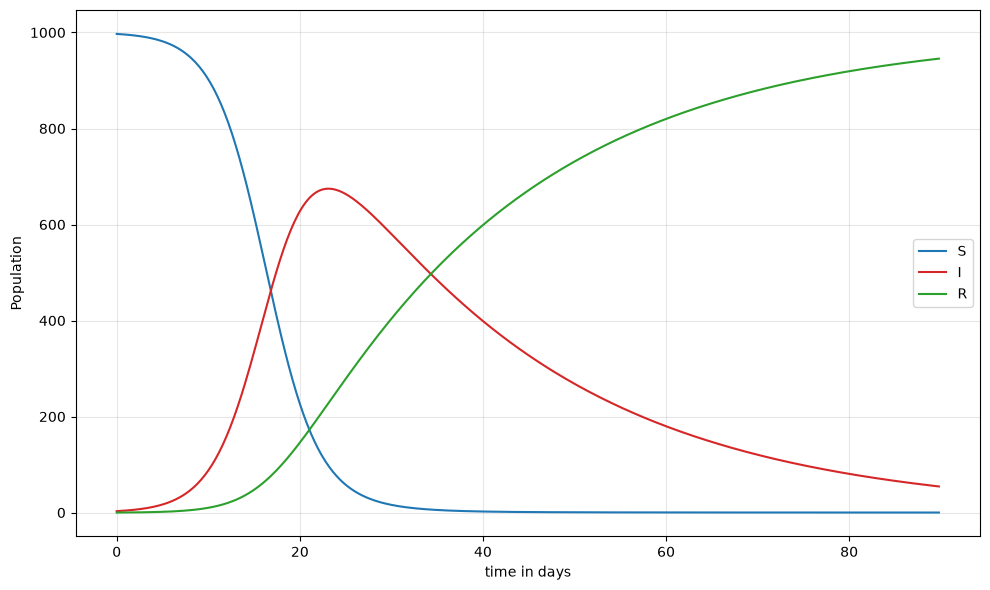

In [5]:
S = status[:,0, 0]
I = status[:,0, 1]
R = status[:,0, 2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(time, S, label="S", color="tab:blue")
ax.plot(time, I, label="I", color="tab:red")
ax.plot(time, R, label="R", color="tab:green")

ax.set_xlabel("time in days")
ax.set_ylabel("Population")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
time,status = region2.euler_solver(delta_t=0.2,T_max=90)

100%|██████████| 449/449 [00:00<00:00, 50194.37it/s]


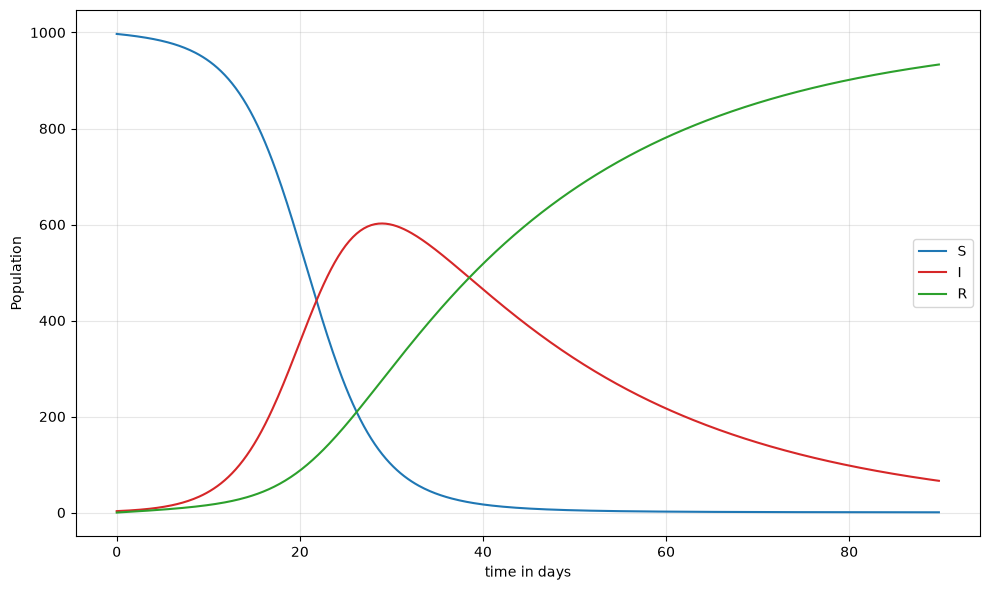

In [7]:
S = status[:,0, 0]
I = status[:,0, 1]
R = status[:,0, 2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(time, S, label="S", color="tab:blue")
ax.plot(time, I, label="I", color="tab:red")
ax.plot(time, R, label="R", color="tab:green")

ax.set_xlabel("time in days")
ax.set_ylabel("Population")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Multiregion class merge

In [8]:
multiregion = multiregion_model([region1,region2],"basic_SIR")

In [11]:
time,status = multiregion.euler_solver(delta_t=0.2,T_max=90)

100%|██████████| 449/449 [00:00<00:00, 51845.68it/s]


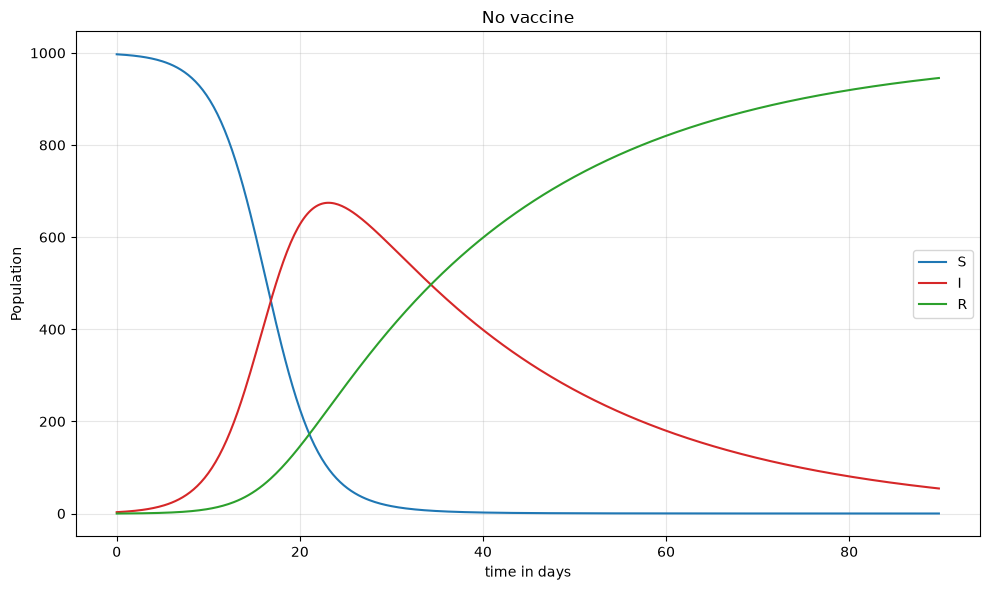

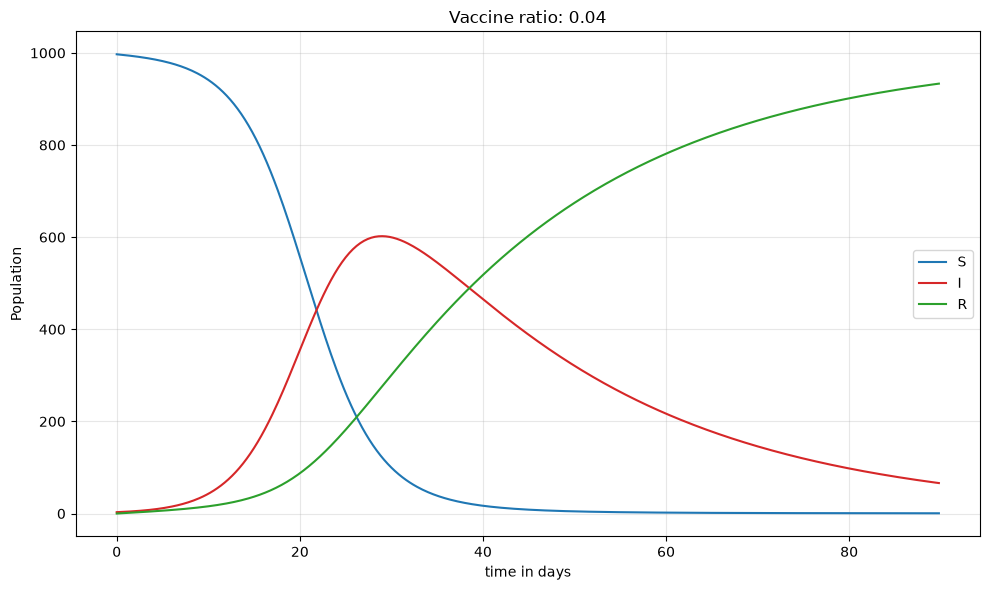

In [14]:
S = status[:,0, 0]
I = status[:,0, 1]
R = status[:,0, 2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(time, S, label="S", color="tab:blue")
ax.plot(time, I, label="I", color="tab:red")
ax.plot(time, R, label="R", color="tab:green")

ax.set_xlabel("time in days")
ax.set_ylabel("Population")
ax.legend()
ax.grid(True, alpha=0.3)

plt.title("No vaccine")
plt.tight_layout()
plt.show()


S = status[:,1, 0]
I = status[:,1, 1]
R = status[:,1, 2]

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(time, S, label="S", color="tab:blue")
ax.plot(time, I, label="I", color="tab:red")
ax.plot(time, R, label="R", color="tab:green")

ax.set_xlabel("time in days")
ax.set_ylabel("Population")
ax.legend()
ax.grid(True, alpha=0.3)

plt.title(f"Vaccine ratio: {multiregion.total_parameters["alpha"][1]}")
plt.tight_layout()
plt.show()